# 2017 — Proximal Policy Optimization (PPO)

**Papers:** John Schulman, Filip Wolski, Prafulla Dhariwal, Alec Radford & Oleg Klimov, *"Proximal Policy Optimization Algorithms"* (2017). Built on TRPO (Schulman et al., 2015) and Generalized Advantage Estimation (GAE, Schulman et al., 2015).

REINFORCE (notebook 12) uses each batch of experience for **one** gradient step, then throws it away, because after the step the data no longer comes from the current policy. Taking several steps on the same batch is far more sample-efficient, but large steps can wreck the policy.

PPO's answer: reuse the batch for several epochs, but **clip** the objective so the new policy cannot move far from the one that collected the data. With the probability ratio $r_t(\theta)=\pi_\theta(a_t|s_t)/\pi_{old}(a_t|s_t)$ and advantage $\hat A_t$:

$$L^{CLIP}(\theta) = \mathbb E_t\Big[\min\big(r_t\hat A_t,\ \operatorname{clip}(r_t, 1-\epsilon, 1+\epsilon)\,\hat A_t\big)\Big]$$

Once an action's probability has moved by more than $\epsilon$ (typically 0.2) in the helpful direction, its gradient is zero. TRPO enforced a similar trust region with a KL constraint and second-order optimisation; PPO gets most of the benefit with plain Adam.

PPO became the default RL algorithm: OpenAI Five (Dota 2), dexterous robot hands, and the RL stage of InstructGPT and ChatGPT (notebook 57).

![Diagram: Proximal Policy Optimization (Schulman et al., 2017)](https://raw.githubusercontent.com/babushkai/neuralnetwork/main/assets/diagrams/38_2017_ppo.png)

In [1]:
import os, math, random, time
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

def get_device():
    """CUDA > Apple MPS > CPU. Force one with the env var NN_DEVICE=cpu|cuda|mps."""
    forced = os.environ.get("NN_DEVICE")
    if forced:
        return torch.device(forced)
    if torch.cuda.is_available():
        return torch.device("cuda")
    if torch.backends.mps.is_available():
        return torch.device("mps")
    return torch.device("cpu")

def seed_everything(seed=0):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)

device = get_device()
torch.set_flush_denormal(True)   # tiny "denormal" floats are extremely slow on CPUs; treat them as 0
seed_everything(0)
print("PyTorch", torch.__version__, "| device:", device)
device = torch.device("cpu")
torch.set_num_threads(1)

PyTorch 2.15.0 | device: mps


In [2]:
class CartPole:
    """Classic cart-pole (Barto, Sutton & Anderson 1983), same constants as Gym's CartPole-v1."""
    g, m_cart, m_pole, half_len, force, dt = 9.8, 1.0, 0.1, 0.5, 10.0, 0.02
    def __init__(self, seed=0): self.rng = np.random.default_rng(seed)
    def reset(self):
        self.s = self.rng.uniform(-0.05, 0.05, 4); self.t = 0; return self.s.astype(np.float32)
    def step(self, action):
        x, x_dot, th, th_dot = self.s
        f = self.force if action == 1 else -self.force
        total, pml = self.m_cart + self.m_pole, self.m_pole * self.half_len
        tmp = (f + pml * th_dot ** 2 * math.sin(th)) / total
        th_acc = (self.g * math.sin(th) - math.cos(th) * tmp) / (self.half_len * (4 / 3 - self.m_pole * math.cos(th) ** 2 / total))
        x_acc = tmp - pml * th_acc * math.cos(th) / total
        self.s = np.array([x + self.dt * x_dot, x_dot + self.dt * x_acc, th + self.dt * th_dot, th_dot + self.dt * th_acc])
        self.t += 1
        failed = abs(self.s[0]) > 2.4 or abs(self.s[2]) > 12 * math.pi / 180
        return self.s.astype(np.float32), 1.0, failed, self.t >= 500

class ActorCritic(nn.Module):
    def __init__(self):
        super().__init__()
        self.pi = nn.Sequential(nn.Linear(4, 64), nn.Tanh(), nn.Linear(64, 64), nn.Tanh(), nn.Linear(64, 2))
        self.v = nn.Sequential(nn.Linear(4, 64), nn.Tanh(), nn.Linear(64, 64), nn.Tanh(), nn.Linear(64, 1))

## Collecting experience and computing GAE advantages
GAE blends one-step TD errors $\delta_t = r_t + \gamma V(s_{t+1}) - V(s_t)$ over many steps: $\hat A_t = \sum_k (\gamma\lambda)^k \delta_{t+k}$. With $\lambda=1$ it is the Monte Carlo return minus $V$ (REINFORCE with a baseline); with $\lambda=0$ it is the one-step TD error.

In [3]:
def collect(env, ac, n_steps, state):
    S, A, LP, R, D, T = [], [], [], [], [], []
    s, ep_len, lengths = state
    for _ in range(n_steps):
        with torch.no_grad():
            dist = torch.distributions.Categorical(logits=ac.pi(torch.from_numpy(s)))
            a = dist.sample()
        s2, r, term, trunc = env.step(a.item())
        S.append(s); A.append(a.item()); LP.append(dist.log_prob(a).item()); R.append(r); D.append(term); T.append(term or trunc)
        ep_len += 1; s = s2
        if term or trunc: lengths.append(ep_len); ep_len = 0; s = env.reset()
    return (np.array(S), np.array(A), np.array(LP, dtype=np.float32), np.array(R, dtype=np.float32), np.array(D), np.array(T), s), (s, ep_len, lengths)

def gae(ac, S, R, D, T, s_last, gamma=0.99, lam=0.95):
    with torch.no_grad():
        V = ac.v(torch.tensor(S)).squeeze(-1).numpy(); v_last = ac.v(torch.from_numpy(s_last)).item()
    adv, run = np.zeros_like(R), 0.0
    for t in reversed(range(len(R))):
        v_next = v_last if t == len(R) - 1 else V[t + 1]
        if T[t]: v_next = 0.0 if D[t] else V[t]                               # terminal: no future; time limit: bootstrap
        delta = R[t] + gamma * v_next - V[t]
        run = delta + gamma * lam * (0.0 if T[t] else run)
        adv[t] = run
    return adv, adv + V

In [4]:
def train(mode, total_steps=60_000, n_steps=2048, epochs=10, mb=64, clip=0.2, seed=0):
    """mode: 'ppo' (clipped, 10 epochs), 'no clip' (same reuse, plain ratio objective), 'one step' (vanilla policy gradient)."""
    seed_everything(seed); env = CartPole(seed); ac = ActorCritic()
    opt = torch.optim.Adam(ac.parameters(), lr=3e-4)
    state = (env.reset(), 0, []); curve, kls, clipfracs = [], [], []
    for it in range(total_steps // n_steps):
        (S, A, LP, R, D, T, s_last), state = collect(env, ac, n_steps, state)
        adv, ret = gae(ac, S, R, D, T, s_last)
        S_, A_, LP_ = torch.tensor(S), torch.tensor(A), torch.tensor(LP)
        adv_, ret_ = torch.tensor(adv), torch.tensor(ret)
        n_epochs = 1 if mode == "one step" else epochs
        for ep in range(n_epochs):
            perm = torch.randperm(n_steps) if mode != "one step" else torch.arange(n_steps)
            batches = [perm[i:i + mb] for i in range(0, n_steps, mb)] if mode != "one step" else [perm]
            for idx in batches:
                logits = ac.pi(S_[idx]); dist = torch.distributions.Categorical(logits=logits)
                logp = dist.log_prob(A_[idx]); ratio = torch.exp(logp - LP_[idx])
                a = adv_[idx]; a = (a - a.mean()) / (a.std() + 1e-8)
                if mode == "ppo": pg = -torch.min(ratio * a, ratio.clamp(1 - clip, 1 + clip) * a).mean()
                else: pg = -(ratio * a).mean()
                v_loss = F.mse_loss(ac.v(S_[idx]).squeeze(-1), ret_[idx])
                loss = pg + 0.5 * v_loss - 0.01 * dist.entropy().mean()
                opt.zero_grad(); loss.backward(); nn.utils.clip_grad_norm_(ac.parameters(), 0.5); opt.step()
        with torch.no_grad():
            new_lp = torch.distributions.Categorical(logits=ac.pi(S_)).log_prob(A_)
            kls.append((LP_ - new_lp).mean().item()); clipfracs.append(((new_lp - LP_).exp().sub(1).abs() > clip).float().mean().item())
        lengths = state[2]
        curve.append(((it + 1) * n_steps, np.mean(lengths[-10:]) if lengths else 0.0))
    return np.array(curve), np.array(kls), np.array(clipfracs)

In [5]:
modes = ["ppo", "no clip", "one step"]
runs = {m: [train(m, seed=s) for s in range(3)] for m in modes}
for m in modes:
    final = np.mean([r[0][-3:, 1].mean() for r in runs[m]])
    print(f"{m:9s} mean episode length at the end (60K env steps): {final:6.1f}   | KL(old‖new) per update {np.mean([r[1].mean() for r in runs[m]]):.4f}  max {np.max([r[1].max() for r in runs[m]]):.3f}")

ppo       mean episode length at the end (60K env steps):  499.0   | KL(old‖new) per update 0.0064  max 0.019
no clip   mean episode length at the end (60K env steps):  284.7   | KL(old‖new) per update 1.0372  max 3.544
one step  mean episode length at the end (60K env steps):   35.7   | KL(old‖new) per update 0.0001  max 0.001


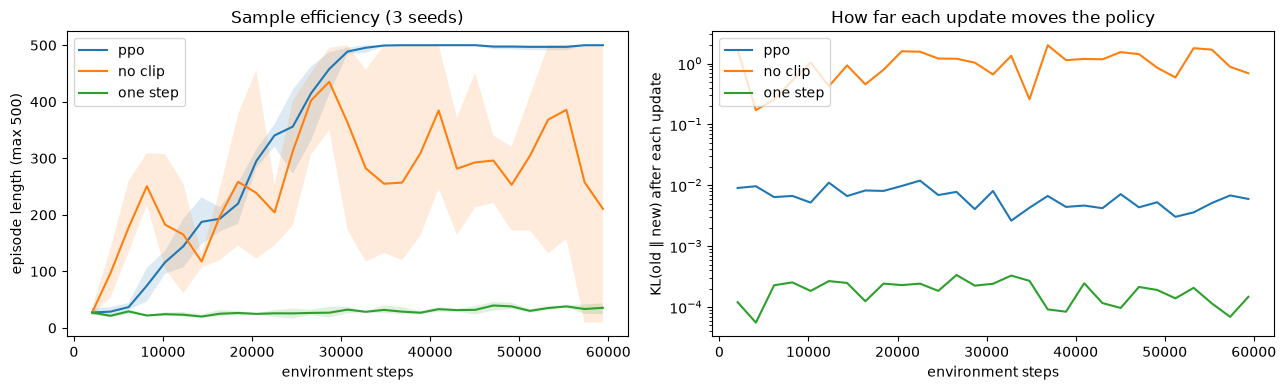

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for m in modes:
    c = np.stack([r[0][:, 1] for r in runs[m]]); x = runs[m][0][0][:, 0]
    axes[0].plot(x, c.mean(0), label=m); axes[0].fill_between(x, c.min(0), c.max(0), alpha=0.15)
    axes[1].semilogy(x, np.stack([np.abs(r[1]) + 1e-6 for r in runs[m]]).mean(0), label=m)
axes[0].set(xlabel="environment steps", ylabel="episode length (max 500)", title="Sample efficiency (3 seeds)"); axes[0].legend()
axes[1].set(xlabel="environment steps", ylabel="KL(old ‖ new) after each update", title="How far each update moves the policy"); axes[1].legend()
plt.tight_layout(); plt.show()

## Takeaways
- **Reuse data, but stay close.** PPO runs ~10 epochs over each batch, which is why it learns much more per environment step than a single policy-gradient step. The clip keeps the policy within a trust region of the data-collecting policy.
- Removing the clip while keeping the reuse lets updates move the policy much further (see the KL plot), which is less stable; how badly it fails depends on the task and step size.
- **Ingredients that stuck:** GAE advantages, a learned value baseline, an entropy bonus, advantage normalization, and gradient clipping. RLHF (notebook 57) uses this exact loop with a language model as the policy and a KL penalty to a reference model; GRPO (notebook 69) keeps PPO's clipped ratio but replaces the value network with group-average rewards.